# Tests: knot placement on Tool Hang

## H26: The speed-rule segment clock marks the precision phases of Tool Hang, and it is a better knot placement than error-driven knots at equal K

Two knot placements per demo, at the same K. No policy training.

- **S (segment clock):** ds/dt = min(w, c/h_min)/c with w = 1/(v + 2 cm/s). v is the commanded grip-site speed, smoothed over 5 steps. c = 3.10 gives a mean of 3 segments/s over the 200 demos. h_min = 0.15 s. The knots are at the integer ticks of s, with K = round(s(T)) and the clock rescaled so that s(T) = K.
- **E (error-driven, B-spline Policy):** start with the end knots, fit, and insert one knot at the middle step of the knot interval with the largest sum of squared fit error (the FITPACK rule in SciPy `generate_knots`, used by the BSP code at commit `61ed5f4`). Repeat until E has the K of S. The knots are chosen with a fast Euclidean fit: a C¹ cubic spline on [p, 2q] (sign-continuous quaternion, so 2|Δq| ≈ the rotation angle in rad). An interval shorter than 2 h_min is never split.

**Scope (changed on 2026-11-15 by user decision):** the demo speed is taken as the marker of precision, so S stays the rule unless E catches something that S misses. The contact phases of step 1 are information only, not a pass criterion. The question is: where does E put clearly more knots than S (E ≥ 2 × S for ≥ 0.5 s), and does S lose something there? The user judges this from videos of the 5 worst demos, with the fit errors and the screened replay success as numbers.

In [1]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

from bezier_rfm.fitting.density import speed_weight
from bezier_rfm.fitting.knots import clock_h, dense_intervals, error_knots, euclidean_proxy, step_density

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TOOL_HANG = ROOT / "data/robomimic/datasets/tool_hang/ph"
CONTROL_DT = 0.05
C = 3.10  # gives a mean of 3 segments/s over the 200 demos
H_MIN = 0.15
D_NEAR = 0.03  # contact phase: object within 3 cm of its pose at the release
WORST = ["demo_189", "demo_82", "demo_66", "demo_16", "demo_137"]

with h5py.File(TOOL_HANG / "low_dim_abs_q0start.hdf5", "r") as f, h5py.File(TOOL_HANG / "low_dim_v15.hdf5", "r") as g:
    NAMES = sorted(f["data"].keys(), key=lambda k: int(k.split("_")[1]))
    ACTIONS = {k: f[f"data/{k}/actions"][:] for k in NAMES}
    OBJECT = {k: g[f"data/{k}/obs/object"][:] for k in NAMES}
len(NAMES)

200

### Step 1: knot density of S and E, with the gripper events and the contact phases

Contact phases come from the `object` observation (base, frame and tool positions at indices 7:10, 21:24, 35:38):
- **C1, hook near base:** between the first grasp and the first release, ‖(p_frame − p_base)(t) − (p_frame − p_base)(t_R1)‖ < 3 cm.
- **C2, tool near hook:** between the tool grasp and the last release, the same test on p_tool − p_frame against t_R2.

The time axis of the all-demo panel is aligned on four anchors: first grasp G1, frame release R1, last grasp G2, last release R2. 9 demos have one extra grasp and release of the tool between R1 and G2.

In [2]:
def contact_masks(actions, obj):
    # Anchors G1, R1, G2, R2 from the gripper command; extra events (9 demos) lie between R1 and G2.
    ev = np.flatnonzero(np.diff(actions[:, 6])) + 1
    g1, r1, g2, r2 = ev[0], ev[1], ev[-2], ev[-1]
    base, frame, tool = obj[:, 7:10], obj[:, 21:24], obj[:, 35:38]
    i = np.arange(len(actions))
    c1 = (i >= g1) & (i <= r1) & (np.linalg.norm((frame - base) - (frame - base)[r1], axis=1) < D_NEAR)
    c2 = (i >= ev[2]) & (i <= r2) & (np.linalg.norm((tool - frame) - (tool - frame)[r2], axis=1) < D_NEAR)
    return np.array([0, g1, r1, g2, r2, len(actions) - 1]), c1, c2


DEMOS = {}
for k in NAMES:
    a = ACTIONS[k]
    hs = clock_h(speed_weight(a), C, H_MIN)
    he = error_knots(euclidean_proxy(a), len(hs), H_MIN)
    anchors, c1, c2 = contact_masks(a, OBJECT[k])
    DEMOS[k] = dict(hs=hs, he=he, anchors=anchors, c1=c1, c2=c2,
                    ds=step_density(hs, len(a)), de=step_density(he, len(a)))
ks = np.array([len(d["hs"]) for d in DEMOS.values()])
total_t = sum(CONTROL_DT * (len(a) - 1) for a in ACTIONS.values())
print(f"K per demo: {ks.min()}-{ks.max()} (median {np.median(ks):.0f}); mean density {ks.sum() / total_t:.2f} segments/s")
print(f"shortest segment: S {min(d['hs'].min() for d in DEMOS.values()):.3f} s, E {min(d['he'].min() for d in DEMOS.values()):.3f} s")

K per demo: 41-134 (median 69); mean density 3.00 segments/s
shortest segment: S 0.149 s, E 0.150 s


phase                time share    S /s    E /s    E/S
C1 hook near base          0.04    2.98    3.11   1.04
C2 tool near hook          0.05    3.77    2.43   0.64
rest                       0.91    2.95    3.04   1.03


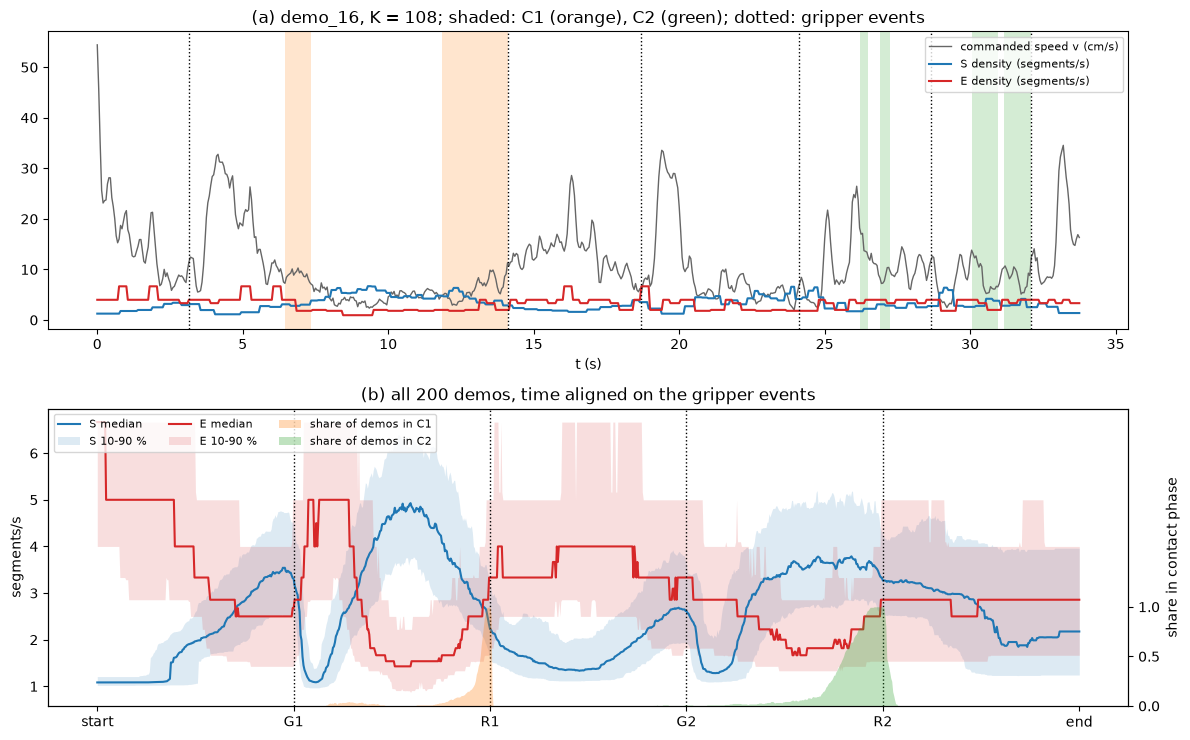

In [3]:
# Knot density pooled over all demos, inside each contact phase and in the rest of the time.
rows = {"C1 hook near base": "c1", "C2 tool near hook": "c2", "rest": None}
print(f"{'phase':<20}{'time share':>11}{'S /s':>8}{'E /s':>8}{'E/S':>7}")
for label, key in rows.items():
    m = np.concatenate([d[key] if key else ~(d["c1"] | d["c2"]) for d in DEMOS.values()])
    s = np.concatenate([d["ds"] for d in DEMOS.values()])[m].mean()
    e = np.concatenate([d["de"] for d in DEMOS.values()])[m].mean()
    print(f"{label:<20}{m.mean():>11.2f}{s:>8.2f}{e:>8.2f}{e / s:>7.2f}")

# Event-aligned time: the 5 sections between the anchors map to [0, 1], ..., [4, 5].
u = np.linspace(0, 5, 1001)
warp = {k: np.interp(u, np.arange(6), CONTROL_DT * d["anchors"]) for k, d in DEMOS.items()}
idx = {k: np.round(w / CONTROL_DT).astype(int) for k, w in warp.items()}
DS = np.array([DEMOS[k]["ds"][idx[k]] for k in NAMES])
DE = np.array([DEMOS[k]["de"][idx[k]] for k in NAMES])
F1 = np.array([DEMOS[k]["c1"][idx[k]] for k in NAMES]).mean(0)
F2 = np.array([DEMOS[k]["c2"][idx[k]] for k in NAMES]).mean(0)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(12, 7.5))
# (a) one demo in real time.
name = "demo_16"
d, a = DEMOS[name], ACTIONS[name]
t = CONTROL_DT * np.arange(len(a))
v = 1.0 / speed_weight(a) - 0.02
for key, color in (("c1", "tab:orange"), ("c2", "tab:green")):
    ax0.fill_between(t, 0, 1, where=d[key], color=color, alpha=0.2, transform=ax0.get_xaxis_transform(), lw=0)
ax0.plot(t, 100 * v, color="0.4", lw=1, label="commanded speed v (cm/s)")
ax0.plot(t, d["ds"], color="tab:blue", lw=1.5, label="S density (segments/s)")
ax0.plot(t, d["de"], color="tab:red", lw=1.5, label="E density (segments/s)")
for e in np.flatnonzero(np.diff(a[:, 6])) + 1:
    ax0.axvline(CONTROL_DT * e, color="k", ls=":", lw=1)
ax0.set(xlabel="t (s)", title=f"(a) {name}, K = {len(d['hs'])}; shaded: C1 (orange), C2 (green); dotted: gripper events")
ax0.legend(loc="upper right", fontsize=8)
# (b) all demos in event-aligned time.
for arr, color, label in ((DS, "tab:blue", "S"), (DE, "tab:red", "E")):
    ax1.plot(u, np.median(arr, 0), color=color, lw=1.5, label=f"{label} median")
    ax1.fill_between(u, *np.percentile(arr, [10, 90], 0), color=color, alpha=0.15, lw=0, label=f"{label} 10-90 %")
ax2 = ax1.twinx()
ax2.fill_between(u, 0, F1, color="tab:orange", alpha=0.3, lw=0, label="share of demos in C1")
ax2.fill_between(u, 0, F2, color="tab:green", alpha=0.3, lw=0, label="share of demos in C2")
ax2.set(ylim=(0, 3), yticks=[0, 0.5, 1], ylabel="share in contact phase")
ax1.set_xticks(np.arange(6), ["start", "G1", "R1", "G2", "R2", "end"])
for x in range(1, 5):
    ax1.axvline(x, color="k", ls=":", lw=1)
ax1.set(ylabel="segments/s", title="(b) all 200 demos, time aligned on the gripper events")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, ncol=3)
fig.tight_layout()

**Step 1 result.**
- Evidence: in C2 (tool near hook), S has 3.77 segments/s and E has 2.43 (E/S = 0.64). In C1 (hook near base), S has 2.98 and E has 3.11. Outside the contact phases both have about 3.0. The S density is highest in the frame carry between G1 and R1 (median about 4.9 /s) and drops to about 2.5 /s in the last second before R1, where C1 is. E is densest at the start of the demo and around G1.
- Interpretation: S marks C2 but not C1. Most of the extra S segments go to the slow carry of the frame, not to the insertion of the frame into the base.

### Step 2: intervals where E is clearly denser than S

An interval is marked where the E density is ≥ 2 × the S density for ≥ 0.5 s. The count over all 200 demos is a check only. The 5 worst demos get fits, a table and videos in the next steps.

In [4]:
INTERVALS = {k: dense_intervals(d["ds"], d["de"]) for k, d in DEMOS.items()}
n_iv = np.array([len(v) for v in INTERVALS.values()])
t_iv = np.array([CONTROL_DT * sum(b - a for a, b in v) for v in INTERVALS.values()])
t_demo = np.array([CONTROL_DT * len(ACTIONS[k]) for k in NAMES])
print(f"all 200 demos: {n_iv.mean():.1f} intervals and {t_iv.mean():.1f} s per demo ({100 * t_iv.sum() / t_demo.sum():.0f} % of the time)")
for k in WORST:
    print(f"{k}: {len(INTERVALS[k])} intervals, {t_iv[NAMES.index(k)]:.1f} s of {t_demo[NAMES.index(k)]:.1f} s")

all 200 demos: 4.3 intervals and 5.6 s per demo (23 % of the time)
demo_189: 5 intervals, 6.5 s of 26.0 s
demo_82: 4 intervals, 5.0 s of 21.1 s
demo_66: 5 intervals, 5.8 s of 23.1 s
demo_16: 5 intervals, 6.2 s of 33.8 s
demo_137: 4 intervals, 5.8 s of 20.3 s


### Step 3: fit error of the S and E fits inside the marked intervals (5 worst demos)

Full R³ × SO(3) fits with the S and E knots (`scripts/fit_knots.py`, files `bezier_h26_{S,E}.hdf5`). The error is between the decoded fit and the raw commands, as RMS over the steps of the interval. The row "rest" covers all steps outside the marked intervals. The interval numbers match the videos in `docs/tool_hang/h26/videos/`.

In [5]:
from scipy.spatial.transform import Rotation

FITS = {}
for rule in ("S", "E"):
    with h5py.File(TOOL_HANG / f"bezier_h26_{rule}.hdf5", "r") as f:
        FITS[rule] = {k: f[f"data/{k}/actions"][:] for k in WORST}


def fit_errors(raw, fitted):
    # Position error (mm) and rotation error (mrad) per step.
    pos = 1000 * np.linalg.norm(fitted[:, :3] - raw[:, :3], axis=1)
    rot = 1000 * (Rotation.from_rotvec(fitted[:, 3:6]).inv() * Rotation.from_rotvec(raw[:, 3:6])).magnitude()
    return pos, rot


rms = lambda x: np.sqrt(np.mean(x**2))
print(f"{'demo':<10}{'#':>5}{'start s':>9}{'end s':>8}{'S /s':>7}{'E /s':>7}{'S pos mm':>10}{'E pos mm':>10}{'S rot mrad':>12}{'E rot mrad':>12}")
for k in WORST:
    d, raw = DEMOS[k], ACTIONS[k]
    (ps, rs), (pe, re) = fit_errors(raw, FITS["S"][k]), fit_errors(raw, FITS["E"][k])
    rest = np.ones(len(raw), bool)
    for n, (a, b) in enumerate(INTERVALS[k], 1):
        rest[a:b] = False
        print(f"{k:<10}{n:>5}{CONTROL_DT * a:>9.2f}{CONTROL_DT * b:>8.2f}{d['ds'][a:b].mean():>7.2f}{d['de'][a:b].mean():>7.2f}"
              f"{rms(ps[a:b]):>10.2f}{rms(pe[a:b]):>10.2f}{rms(rs[a:b]):>12.2f}{rms(re[a:b]):>12.2f}")
    print(f"{k:<10}{'rest':>5}{'':>17}{d['ds'][rest].mean():>7.2f}{d['de'][rest].mean():>7.2f}"
          f"{rms(ps[rest]):>10.2f}{rms(pe[rest]):>10.2f}{rms(rs[rest]):>12.2f}{rms(re[rest]):>12.2f}")

demo          #  start s   end s   S /s   E /s  S pos mm  E pos mm  S rot mrad  E rot mrad
demo_189      1     3.20    5.80   1.76   5.00     10.01      7.90        9.89        3.29
demo_189      2    17.00   17.85   1.14   3.68      7.73      4.18        5.90        2.34
demo_189      3    18.15   19.80   1.97   4.85      8.94      7.08        3.50        1.30
demo_189      4    19.85   20.75   1.15   2.50      5.22      3.19        9.17        3.09
demo_189      5    25.45   25.95   1.35   4.40     12.79      2.20        9.04        1.68
demo_189   rest                    3.27   2.35      3.88      3.61        4.70        2.11
demo_82       1     0.00    0.95   1.06   3.13      8.44      5.64       11.02        4.29
demo_82       2     2.65    4.95   1.51   5.13     15.96     13.51        9.58        4.31
demo_82       3    11.20   12.05   1.27   4.31      9.31      7.55        8.44        1.86
demo_82       4    13.50   14.40   1.11   3.02      6.32      5.16        5.18        2.63

**Step 3 result.**
- Evidence: in 24 of 24 marked intervals, the E fit has a lower position and rotation error than the S fit. The rotation error of S in the intervals is 3.5–26 mrad, against 1.3–4.3 mrad for E. Outside the intervals the position errors are about equal (3.8–5.3 mm), and the E rotation error stays lower (1.8–2.3 vs 2.3–4.7 mrad). Over the whole demo: S 5.7–7.7 mm and 4.2–7.9 mrad, E 4.5–6.6 mm and 2.0–2.6 mrad.
- Interpretation: none here. The user judges the intervals from the videos.

### Step 4: screened replay of the S and E fits (5 worst demos, 30 runs)

H25.6 protocol (`scripts/screen_replay.py`): nominal run plus 5 runs with 0.2 mm / 0.2 mrad command noise, 60 hold steps. The references come from the H25.4 and H25.6 screening files on the same demos and seeds. The sign test counts the runs where only one of S and E succeeds.

In [2]:
import json
from scipy.stats import binomtest

SCREENING = ROOT / "docs/tool_hang/screening"
files = {"raw (q0-start)": "h25_4_reference", "U 3 /s": "h25_4_uniform_rho3", "old speed rule": "h25_6_speed_rho3",
         "S (H26)": "h26_S", "E (H26)": "h26_E"}
RUNS = {}
for label, name in files.items():
    runs = json.loads((SCREENING / f"{name}.json").read_text())["runs"]
    RUNS[label] = {(r["demo"], r["seed"]): r["success_with_hold"] for r in runs if r["demo"] in WORST}
print(f"{'':<16}" + "".join(f"{k:>10}" for k in WORST) + f"{'total':>8}")
for label, runs in RUNS.items():
    per = [sum(v for (d, _), v in runs.items() if d == k) for k in WORST]
    print(f"{label:<16}" + "".join(f"{p:>10}" for p in per) + f"{sum(per):>5} / {len(runs)}")
keys = sorted(RUNS["S (H26)"])
s_only = sum(RUNS["S (H26)"][x] and not RUNS["E (H26)"][x] for x in keys)
e_only = sum(RUNS["E (H26)"][x] and not RUNS["S (H26)"][x] for x in keys)
p = binomtest(s_only, s_only + e_only).pvalue if s_only + e_only else 1.0
print(f"S only: {s_only}, E only: {e_only}, sign test p = {p:.3f}")

                  demo_189   demo_82   demo_66   demo_16  demo_137   total
raw (q0-start)           6         6         6         6         6   30 / 30
U 3 /s                   1         2         2         4         4   13 / 30
old speed rule           1         4         5         5         6   21 / 30
S (H26)                  0         2         4         5         6   17 / 30
E (H26)                  1         4         4         0         0    9 / 30
S only: 14, E only: 6, sign test p = 0.115


**Step 4 result.**
- Evidence: S succeeds in 17 of 30 runs, E in 9 of 30 (raw 30, U 3 /s 13, old speed rule 21). S succeeds alone in 14 runs, E alone in 6 (sign test p = 0.115). E fails all 12 runs of demo_16 and demo_137. In the nominal video of demo_16, raw and S succeed and E fails.
- Interpretation: the lower fit error of E (step 3) does not give a higher replay success. The S vs E difference is not significant at 30 runs.

Video: `docs/tool_hang/h26/videos/demo_16_h26.mp4` (raw, S fit, E fit; time stamp and interval number in the bottom strip).

### H26 closed (2026-11-16)

- **Status:** rejected. E does not catch parts that S misses. S stays the knot placement.
- **Verdict:** after the demo_16 video, the user judged that S puts more segments where they are relevant, and that E adds density at places that are not significant for task success. This is the user's judgement from the video, not the result of a significance test.
- **Evidence (unchanged):** S 17 of 30, E 9 of 30 (sign test p = 0.115). E has the lower fit error in all 24 marked intervals.
- **Clock S against the old speed rule** (same demos and seeds): 17 vs 21 of 30 (old only 5, S only 1, p = 0.22). The fits differ in K per demo and in the event knots (old fits only). No control run separates the two, so the cause is not known. 17 of 30 is the reference value for the clock form.